In [1]:
# install matplotlib widget to enable live slider
%pip install ipympl
%matplotlib widget

# imports
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider

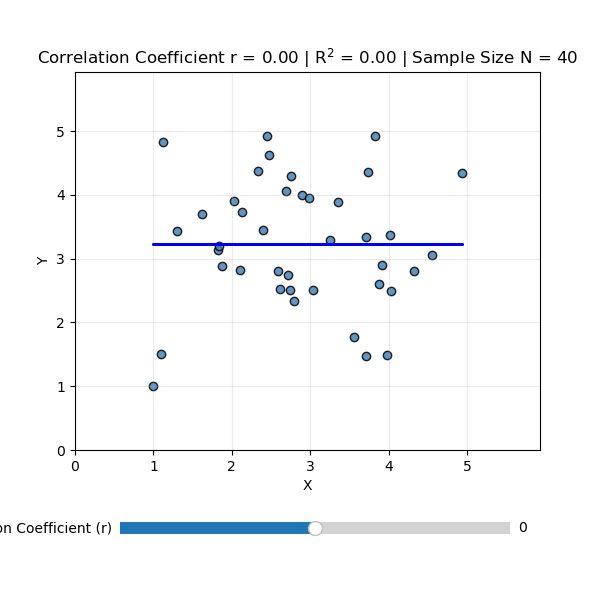

In [5]:
# Initial correlation
r_initial = 0

# Reproducible dataset (fixed seed)
n = 40
rng = np.random.default_rng(67)

x0 = rng.normal(size=n)
x0 = (x0 - x0.mean()) / x0.std(ddof=1)

z = rng.normal(size=n)
z -= z.mean()
z -= np.dot(z, x0) / np.dot(x0, x0) * x0
z /= z.std(ddof=1)

# generate y values and force them to be positive
def make_y(r):
    y = r * x0 + np.sqrt(max(0, 1 - r**2)) * z
    return y - y.min() + 1

x = x0 - x0.min() + 1 # positive x values
y = make_y(r_initial)


# Create figure
fig, ax = plt.subplots(figsize=(6, 6))
plt.subplots_adjust(bottom=0.25)

scatter = ax.scatter(x, y, color="steelblue",
                     edgecolor="black", alpha=0.85)

# Add line of best fit
slope, intercept = np.polyfit(x, y, 1)
line, = ax.plot(
    x, slope * x + intercept,
    color="blue",
    linewidth=2,
    label="Line of best fit"
)

title = ax.set_title("")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_xlim(0, x.max() + 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)

def update_plot(r):
    y = make_y(r)
    scatter.set_offsets(np.column_stack((x, y)))

    # Recalculate and update line of best fit
    slope, intercept = np.polyfit(x, y, 1)
    line.set_ydata(slope * x + intercept)
    
    # Update vertical axis to fit the data
    ax.set_ylim(0, y.max() + 1)

    r_squared = np.dot(r,r)
    title.set_text(
        f"Correlation Coefficient r = {r:.2f} | R$^2$ = {r_squared:.2f} | Sample Size N = {n}"
    )
    fig.canvas.draw_idle()

# create slider
slider_ax = fig.add_axes([0.20, 0.10, 0.65, 0.04])
r_slider = Slider(
    ax=slider_ax,
    label="Correlation Coefficient (r)",
    valmin=-1.0,
    valmax=1.0,
    valinit=r_initial,
    valstep=0.05
)

r_slider.on_changed(update_plot)

update_plot(r_initial)
plt.show()
